In [52]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_2, MUDO     = "#52514e", "#898781"
GRADE, EIXO       = "#e1e0d9", "#c3c2b7"
REAL, PREDITO     = "#2a78d6", "#eb6834"   # slots categoricos 1 e 2
ERRO_CLARO, MAE_ESC = "#86b6ef", "#184f95" # rampa azul: degraus 250 e 600

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"],
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
})



SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios


DATA_DIR = Path.cwd().parent / "data" / "processed"
OUT_DIR = Path.cwd().parent / "data" / "splited"

print(f"dados em {DATA_DIR}")
print(f"semente: {SEED}")

dados em c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\processed
semente: 42


In [53]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("*.csv"))
)
CAMINHOS = {p.stem: p for p in ARQUIVOS}   # para reconferir contra o CSV bruto no fim
print(f"{len(ARQUIVOS)} arquivos" + NL)

def enfeitar(ax, titulo, xlabel, ylabel):
        ax.set_title(titulo, color=TINTA, fontsize=12, loc="left", pad=10)
        ax.set_xlabel(xlabel, color=TINTA_2, fontsize=10)
        ax.set_ylabel(ylabel, color=TINTA_2, fontsize=10)
        ax.grid(True, color=GRADE, linewidth=0.6, linestyle="-")
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        for lado in ("left", "bottom"):
            ax.spines[lado].set_color(EIXO)
        ax.tick_params(colors=MUDO, labelsize=9)

def load_file(p: Path):
    df = pd.read_csv(p, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    df["datetime"] = pd.to_datetime(df["datetime"])
    return df

partes = []
for p in ARQUIVOS:
    df = load_file(p)
    df['station'] = p.stem
    partes.append(df)
    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

def show_dataset(dataset: pd.DataFrame):
    # A ordem das colunas difere entre os schemas; a uniao e por nome.
    print(NL + f"pool: {len(dataset)} linhas, {dataset.shape[1]} colunas")
    print(NL + "nulos por coluna (so as que tem):")
    nulos = dataset.isna().sum()
    print(nulos[nulos > 0].to_string() if (nulos > 0).any() else "  (nenhum)")
    print(NL + "colunas com zero:")
    zeros = dataset.isin([0]).sum()
    print(zeros[zeros > 0].to_string() if (zeros > 0).any() else "  (nenhum)")
    return dataset
    


raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

6 arquivos

  processed  ifpec1              4177 linhas  19 colunas
  processed  ifpec2              4177 linhas  19 colunas
  processed  ifpec3              4177 linhas  19 colunas
  processed  ifpee1             16653 linhas  19 colunas
  processed  ifpee2              4177 linhas  19 colunas
  processed  ifpee3              4177 linhas  19 colunas


In [54]:

df = show_dataset(raw.copy())


pool: 37538 linhas, 19 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA           1812
ghit             8
sintetico    37254


In [55]:
df = df.sort_values(["station", "datetime"])
for _, g in df.groupby("station"):
    grade = pd.date_range(g["datetime"].min().floor("D"), g["datetime"].max(), freq="h")
    serie = g.set_index("datetime")["PCA"].reindex(grade).fillna(0.0)
    df.loc[g.index, "PCA_lag1"] = serie.shift(1).reindex(g["datetime"]).to_numpy()

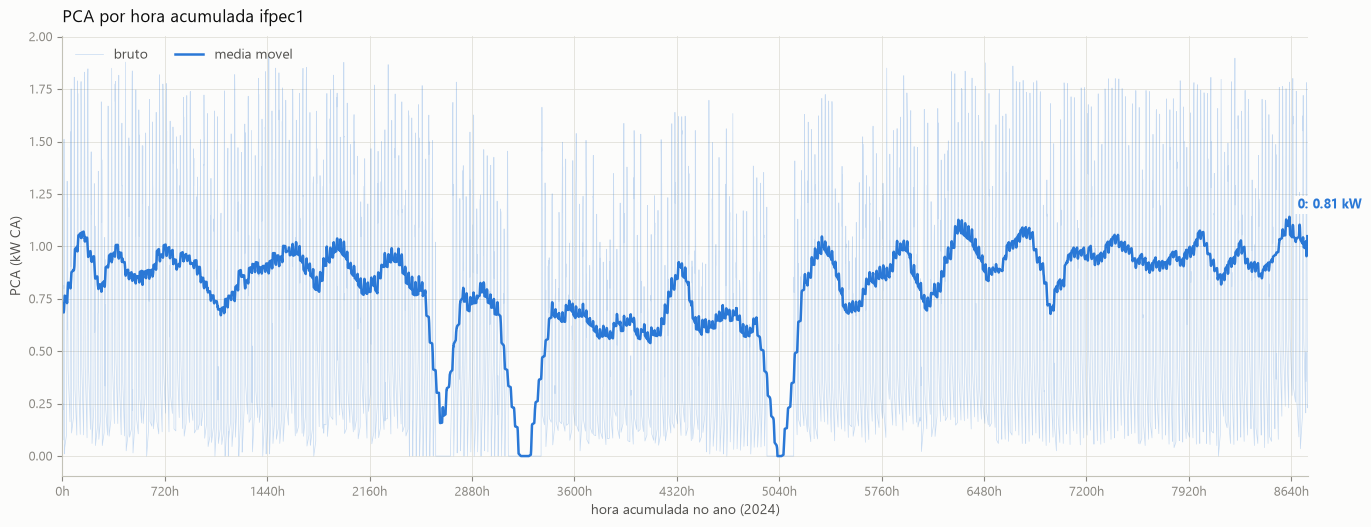

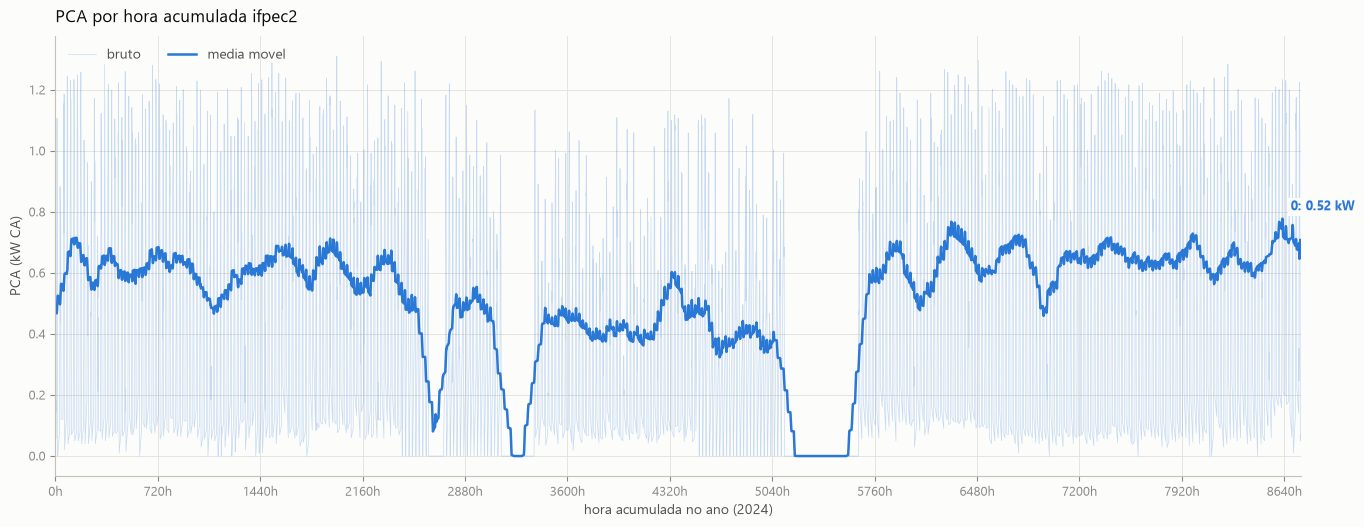

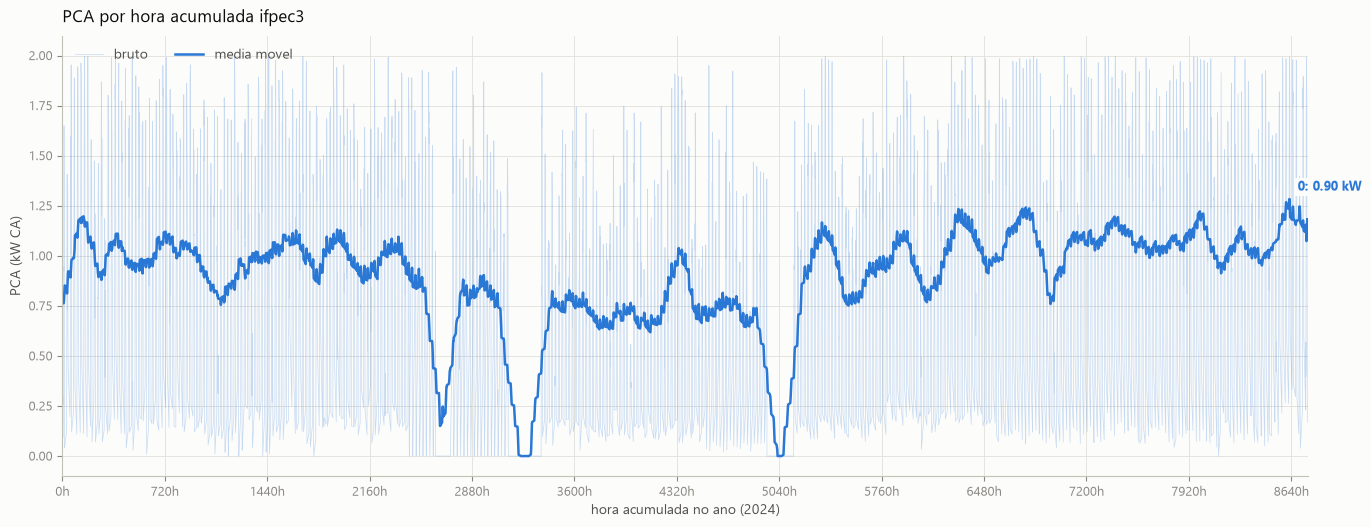

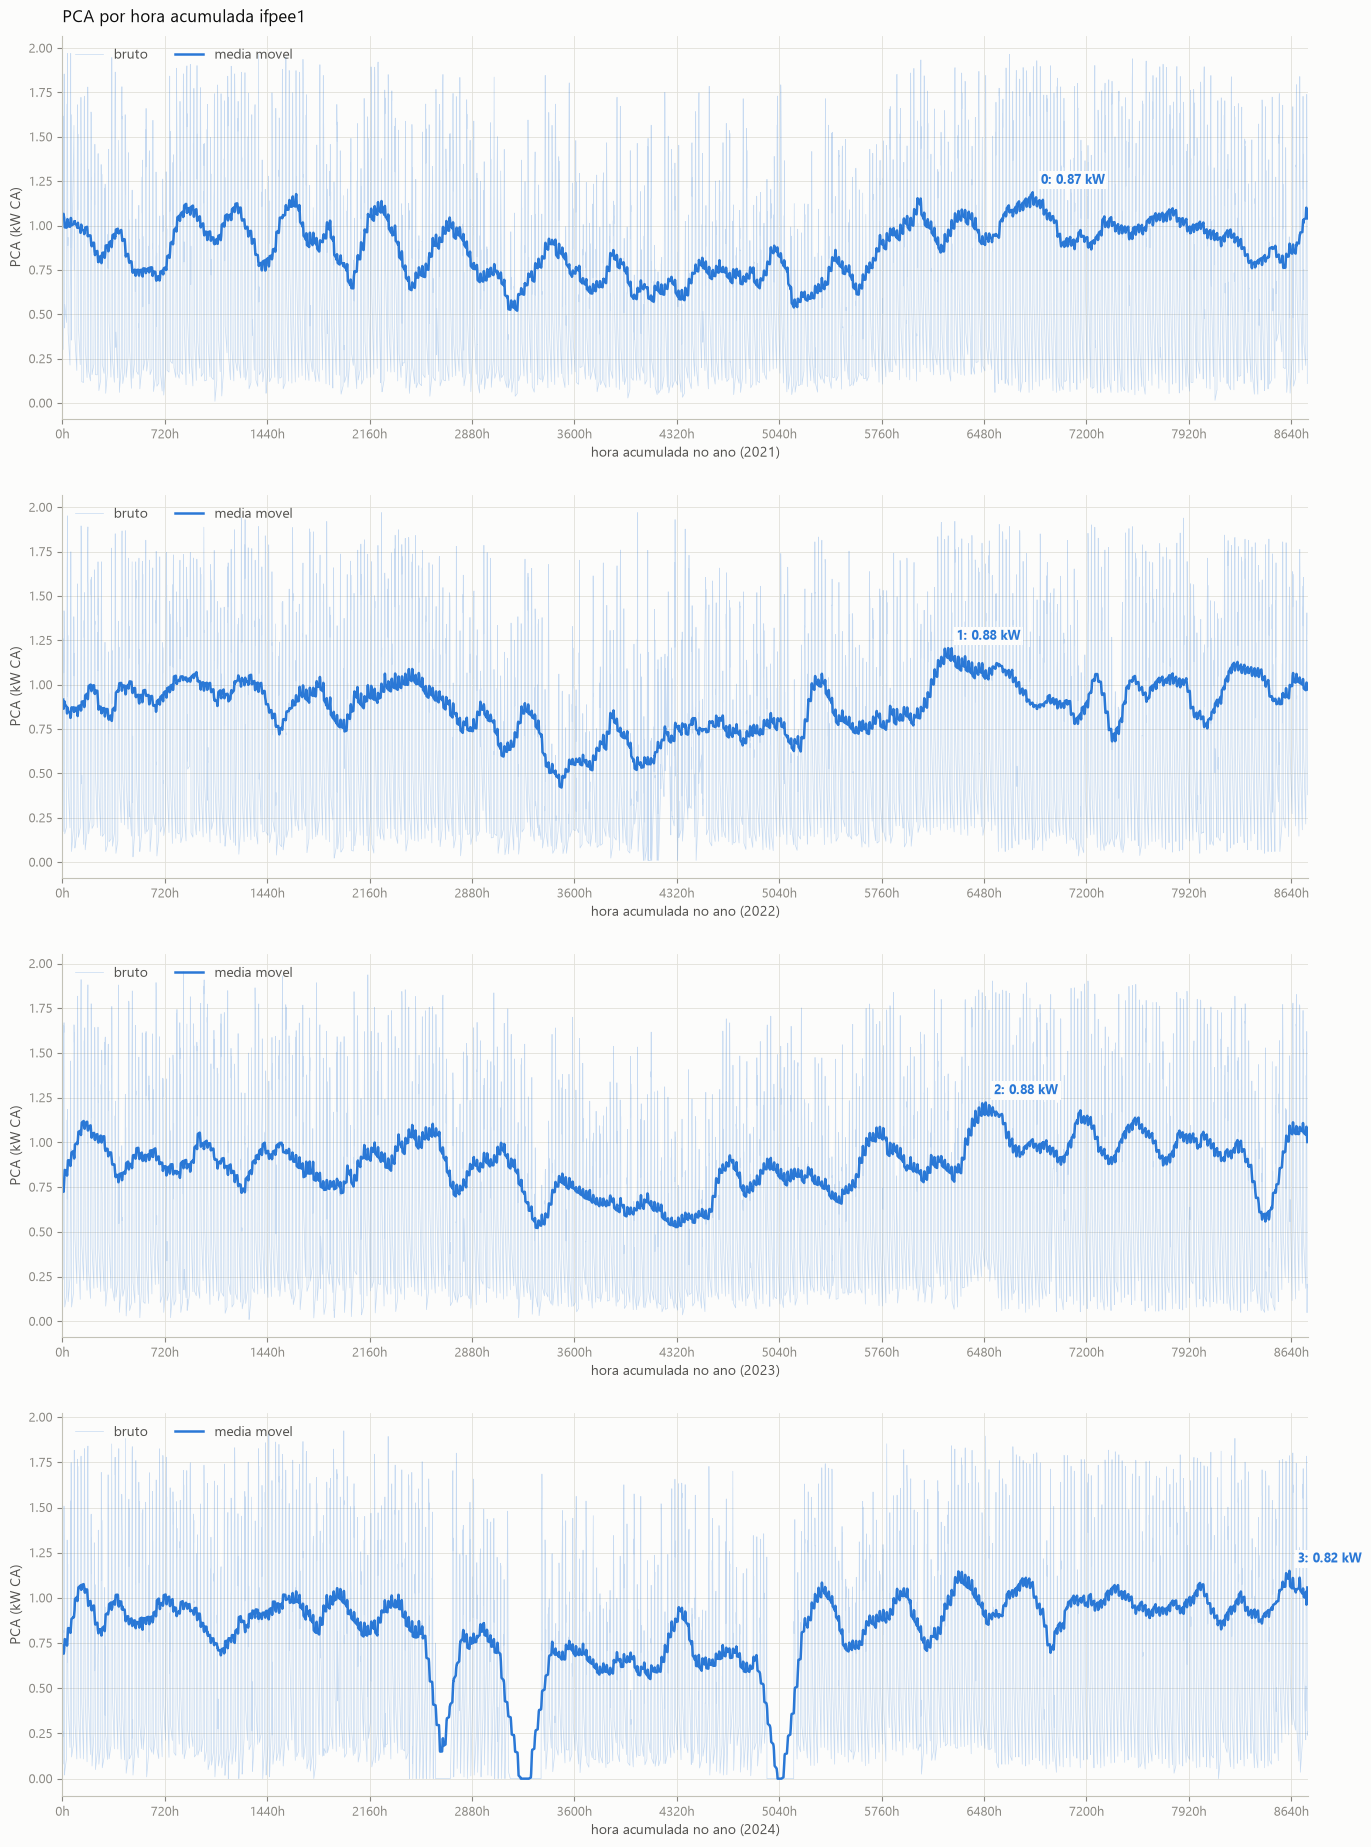

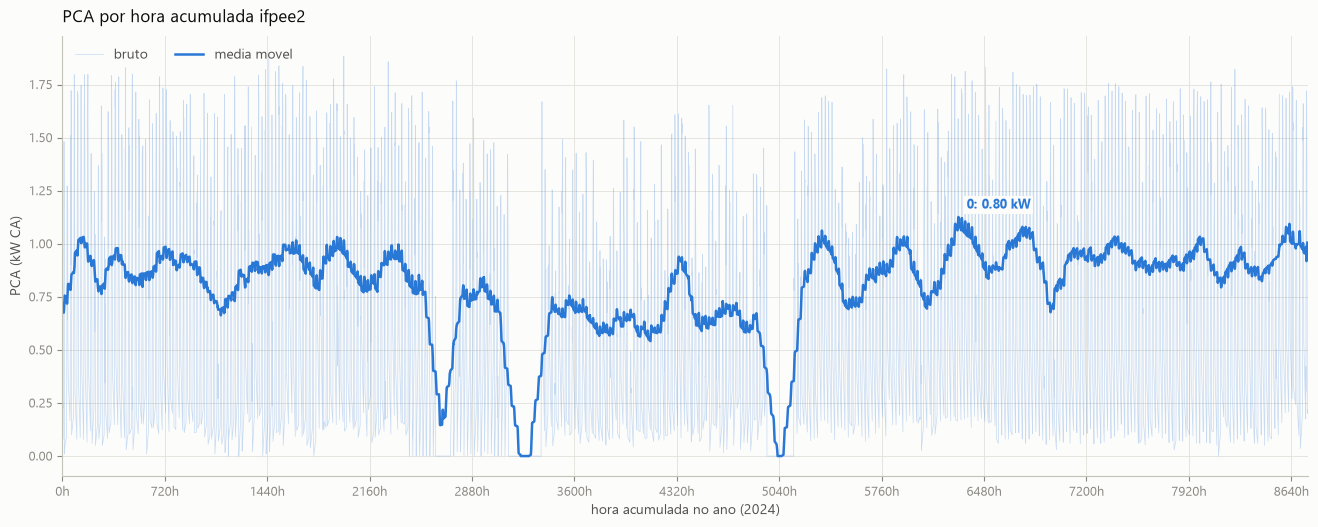

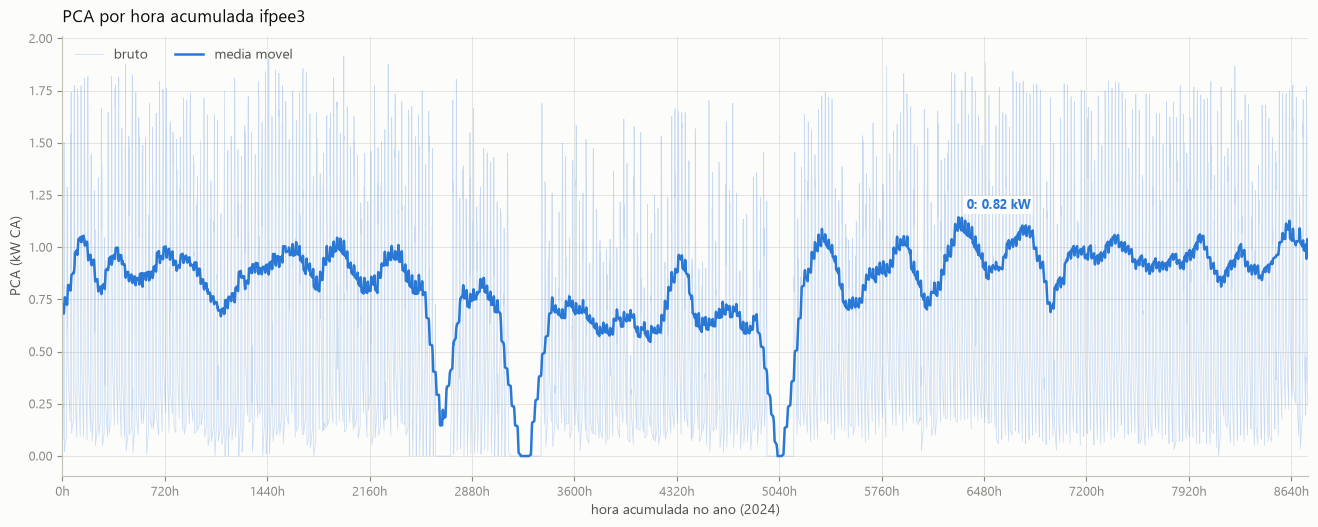

In [56]:
STATIONS = df.station.unique()

def plot_dataset(df: pd.DataFrame, station: str = None):
    STATION = station if station is not None else df["station"].unique()[0]
    df_eval = df.copy()[["datetime", "PCA"]].sort_values("datetime").reset_index()

    # --- Comparacao sazonal do PCA: start vs end --------------------------------
    # df_eval tem somente index / datetime / PCA (start-end).
    df_eval["ano"]  = df_eval["datetime"].dt.year
    df_eval["mes"]  = df_eval["datetime"].dt.month
    df_eval["doy"]  = df_eval["datetime"].dt.dayofyear
    df_eval.loc[df_eval["doy"] == 366, "doy"] = 365
    df_eval["hora"] = df_eval["datetime"].dt.hour
    # hora acumulada no ano: hora 0 do dia 1 = 0, ...  (doy-1)*24 + hora
    df_eval["hora_ano"] = (df_eval["doy"] - 1) * 24 + df_eval["hora"]

   
    HALO = dict(facecolor=SUPERFICIE, edgecolor="none", pad=2.0)
    ANOS = sorted(df_eval["ano"].unique())

    # --- 1. curva horaria acumulada ao longo do ano ----------------------------
    # x = hora acumulada no ano (0 .. 8760 h)
    # valor bruto (linha fina) + media movel de 1 semana (linha grossa).
    cor = REAL
    H_SIZE = len(ANOS) * 5.5
    fig, axs = plt.subplots(nrows=len(ANOS), figsize=(14, H_SIZE))
  
    for i, ano in enumerate(ANOS):
        if len(ANOS) > 1:
            ax = axs[i]
        else:
            ax = axs
        
        d = df_eval[df_eval["ano"] == ano].sort_values("hora_ano").copy()
        # valor bruto
        ax.plot(d["hora_ano"], d["PCA"], color=cor, lw=0.5, alpha=0.25, label="bruto")
        # media movel
        JANELA = 1 + len(d) // 60
        mm = d["PCA"].rolling(window=JANELA, center=True, min_periods=1).mean()
        ax.plot(d["hora_ano"], mm, color=cor, lw=1.8, label="media movel")
        imax = mm.idxmax()
        ax.annotate(f"{i}: {d['PCA'].mean():.2f} kW",
                    (d["hora_ano"].loc[imax], mm.loc[imax]),
                    xytext=(6, 6), textcoords="offset points",
                    color=cor, fontsize=9, fontweight="bold", bbox=HALO)
        enfeitar(ax, f"PCA por hora acumulada {STATION}" if not i else None, f"hora acumulada no ano ({ano})", "PCA (kW CA)")
        ax.set_xlim(0, 365 * 24)
        ticks = np.arange(0, 365 * 24 + 1, 24 * 30)   # ~a cada 30 dias
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"{int(t)}h" for t in ticks])
        ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2, ncol=2)

    fig.subplots_adjust(top=0.87, bottom=0.07, left=0.07, right=0.96)
    plt.show()

for station in STATIONS:
  plot_dataset(df[df.station == station], station=station)


In [57]:
TARGET_STATION = "ifpee1"
REGRESSION_TARGET = ("PCA","PCA_lag1")
INDEX_COLS = ("datetime",)
FEATURES = (
  "ghit","jacques","temperatura_ambiente","sin1","cos1","sintetico"
)

# transform sintetico from boolean to 0-1 range
df["sintetico"] = df["sintetico"].astype(int)

SELECTED_COLS = [*INDEX_COLS, *REGRESSION_TARGET, *FEATURES]
df_split = df[df.station == TARGET_STATION][SELECTED_COLS].copy()
df_split = df_split.sort_values("datetime").reset_index(drop=True)

df_train = df_split[df_split.datetime.dt.year < 2023]
df_val = df_split[df_split.datetime.dt.year == 2023]
df_test = df_split[df_split.datetime.dt.year == 2024]

In [58]:
if not OUT_DIR.exists():
  OUT_DIR.mkdir()

df_train.to_csv(OUT_DIR / "train.csv", index=False)
df_val.to_csv(OUT_DIR / "validation.csv", index=False)
df_test.to_csv(OUT_DIR / "test.csv", index=False)

OUT_DIR = OUT_DIR / "test"

if not OUT_DIR.exists():
  OUT_DIR.mkdir()

for station in STATIONS:
  df[df.station == station].to_csv(OUT_DIR / f"{station}.csv", index=False)